# 01. R4 결과 표 읽기 (재학습 없음)

저장소에 올라간 작은 표만 읽는다. 서버 자료·GPU가 필요 없다.

- 과제: **학습에 한 번도 쓰지 않은 약물**(모든 세포주에서 제외)의 처리 후 RNA 변화(978개 유전자)를, 처리 전 RNA(X0)와 약물 구조(ECFP)만으로 예측한다.
- 점수 **ΔRMSE**: 예측한 변화와 실제 변화의 차이. **낮을수록 좋다.**
- W0 = 공개 WAVE 원형, W1 = 같은 부품으로 변화량을 직접 예측하도록 바꾼 모델, W2 = W1 + "실측 반응이 비슷한 약물끼리 가깝게" 학습하는 보조 목적.

In [1]:
import os, json, sys
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
ROOT = os.environ.get("R4_ROOT", os.getcwd())
os.chdir(ROOT); sys.path.insert(0, ROOT)
pd.set_option("display.width", 200); pd.set_option("display.float_format", lambda v: f"{v:.4f}")
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8983"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8983", "font.size": 10,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
MAN = "manifests/response_geometry_r4"

## 1. 시험 약물 결과 (동결 후 한 번 채점)

In [2]:
t = pd.read_csv(f"{MAN}/test_summary.tsv", sep="\t")
piv = t.pivot(index="model", columns="panel", values="rmse_mean")[["source", "HUH7", "JHH5", "JHH7", "hcc_mean"]]
print("test delta RMSE (seed mean; source = family-equal mean over non-HCC families)")
print(piv.sort_values("source").to_string())

test delta RMSE (seed mean; source = family-equal mean over non-HCC families)
panel                source   HUH7   JHH5   JHH7  hcc_mean
model                                                     
ecfp_x0_ridge        0.5375 0.6333 0.5107 0.6494    0.5978
cellmean_ecfp_ridge  0.5424 0.6455 0.5187 0.6521    0.6054
train_cell_mean      0.5426 0.6466 0.5166 0.6552    0.6061
W2_proposed          0.5500 0.6771 0.5218 0.6904    0.6298
W2_before_mod1       0.5502 0.6748 0.5226 0.6894    0.6289
W1_delta_anchor      0.5505 0.6783 0.5213 0.6901    0.6299
latent_regression    0.5509 0.6750 0.5220 0.6902    0.6291
delta_mlp            0.5515 0.6758 0.5210 0.6806    0.6258
no_change            0.5567 0.6938 0.5194 0.7043    0.6392
W0_native            0.7090 0.7697 0.6002 0.9174    0.7624


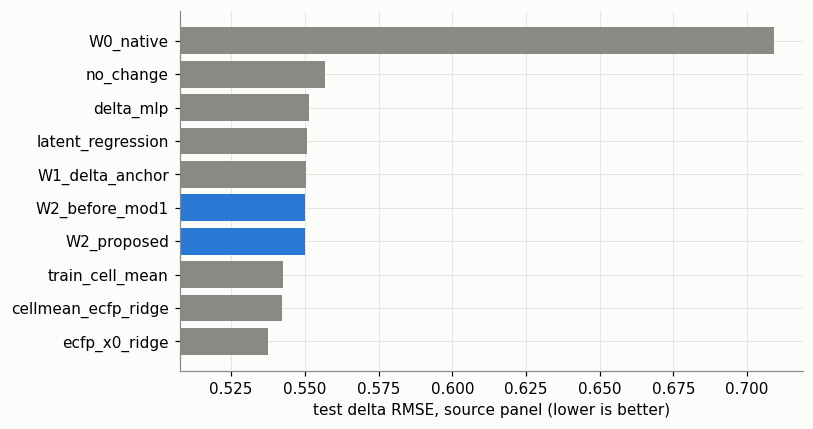

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4))
p = piv.sort_values("source")
ax.barh(p.index, p["source"], color=[BLUE if m.startswith("W2") else GREY for m in p.index])
ax.set_xlim(p["source"].min() - 0.03, p["source"].max() + 0.01)
ax.set_xlabel("test delta RMSE, source panel (lower is better)")
plt.tight_layout(); plt.show()

## 2. 짝 비교 (약물 그룹 bootstrap 95% 구간)

차이 = a − b. 구간 전체가 0보다 작아야 a가 더 낫다고 말한다.

In [4]:
c = pd.read_csv(f"{MAN}/test_contrasts.tsv", sep="\t")
print(c[c.panel.isin(["source", "hcc_mean"])].to_string(index=False))

              a                 b    panel    diff      lo      hi
W1_delta_anchor         W0_native   source -0.1585 -0.1677 -0.1376
W1_delta_anchor         W0_native hcc_mean -0.1325 -0.1562 -0.1108
    W2_proposed   W1_delta_anchor   source -0.0005 -0.0026  0.0017
    W2_proposed   W1_delta_anchor hcc_mean -0.0001 -0.0025  0.0027
    W2_proposed latent_regression   source -0.0009 -0.0020  0.0005
    W2_proposed latent_regression hcc_mean  0.0007 -0.0014  0.0029
    W2_proposed     ecfp_x0_ridge   source  0.0125  0.0033  0.0217
    W2_proposed     ecfp_x0_ridge hcc_mean  0.0320  0.0119  0.0525
    W2_proposed   train_cell_mean   source  0.0073 -0.0018  0.0167
    W2_proposed   train_cell_mean hcc_mean  0.0237  0.0009  0.0455
W1_delta_anchor   train_cell_mean   source  0.0078 -0.0014  0.0180
W1_delta_anchor   train_cell_mean hcc_mean  0.0238  0.0007  0.0457
  ecfp_x0_ridge   train_cell_mean   source -0.0051 -0.0075 -0.0022
  ecfp_x0_ridge   train_cell_mean hcc_mean -0.0083 -0.0134 -0.

## 3. 반응 크기별 오차

실제 반응이 약한 약물과 강한 약물에서 오차가 어떻게 다른지 본다(채점용 구분이며 설정 선택에 쓰지 않았다).

In [5]:
s = pd.read_csv(f"{MAN}/test_by_strength.tsv", sep="\t")
print(s.pivot(index="model", columns="tertile", values="rmse")[["weak", "mid", "strong"]].to_string())

tertile               weak    mid  strong
model                                    
W0_native           0.5292 0.6349  0.8299
W1_delta_anchor     0.3321 0.4601  0.7385
W2_before_mod1      0.3323 0.4598  0.7373
W2_proposed         0.3324 0.4608  0.7369
cellmean_ecfp_ridge 0.3654 0.4634  0.7004
delta_mlp           0.3393 0.4612  0.7350
ecfp_x0_ridge       0.3633 0.4606  0.6909
latent_regression   0.3348 0.4622  0.7354
no_change           0.3243 0.4581  0.7614
train_cell_mean     0.3618 0.4614  0.7042
